# MLP from scratch Infernece and initialization studies 

In [1]:
import sys
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add parent directory to path to access the src module
sys.path.append(os.path.abspath('..')) 

# Import custom modules from the src folder
from src.data_loader import load_svhn_data
from src.features import extract_flattened, extract_pca
from src.mlp import MLPFromScratch

# 1. Load SVHN Dataset using data_loader.py
# normalize=True scales data to [0-1]
print("--- Loading Dataset ---")
X_train_raw, y_train, X_test_raw, y_test = load_svhn_data(
    data_dir="../data/raw", 
    n_train=15000, 
    n_test=3000, 
    random_state=42, 
    normalize=True
)

# 2. Extract Flattened Features (and standardize) using features.py
print("\n--- Extracting Flattened Features ---")
X_train_flat, X_test_flat = extract_flattened(X_train_raw, X_test_raw, standardize=True)
print(f"Flattened dimensions: Train: {X_train_flat.shape}, Test: {X_test_flat.shape}")

# 3. Extract PCA Features using features.py 
# (Using 53 components for fast MLP execution)
print("\n--- Extracting PCA Features ---")
X_train_pca, X_test_pca, pca_model = extract_pca(X_train_flat, X_test_flat, n_components=53, random_state=42)
print(f"PCA dimensions: Train: {X_train_pca.shape}, Test: {X_test_pca.shape}")

--- Loading Dataset ---
Loading SVHN Dataset
Dataset Loaded. Train: (15000, 3, 32, 32), Test: (3000, 3, 32, 32)

--- Extracting Flattened Features ---
Flattened dimensions: Train: (15000, 3072), Test: (3000, 3072)

--- Extracting PCA Features ---
PCA dimensions: Train: (15000, 53), Test: (3000, 53)


In [13]:
# Network Hyperparameters
hidden_layers = [128,128]

# Initialization methods to test
init_methods = ['zeros', 'random', 'Xavier', 'he', 'optimal']
results = []
histories = {}

print("Starting Initialization Experiment...\n" + "-"*45)

for method in init_methods:
    print(f"\nTraining with initialization method: {method}...")
    
    # 1. Initialize our custom MLPFromScratch model
    mlp = MLPFromScratch(
        input_size=X_train_pca.shape[1], 
        hidden_layers=hidden_layers, 
        num_classes=10, 
        init_method=method,
        activation_func="relu"
    )
    
    # 2. Time the Training Phase & Collect History 
    # Note: We pass the Test Set as Validation Set to record val_loss per epoch
    t0_fit = time.time()
    histories[method] = mlp.fit(
        X_train_pca, y_train, 
        X_val=X_test_pca, 
        y_val=y_test,
    )
    fit_time = time.time() - t0_fit
    
    # 3. Time the Prediction Phase
    t0_pred = time.time()
    probs_train = mlp.forward(X_train_pca)
    probs_test = mlp.forward(X_test_pca)
    
    # Get class predictions by finding the argmax of the probabilities
    y_pred_train = np.argmax(probs_train, axis=1)
    y_pred_test = np.argmax(probs_test, axis=1)
    pred_time = time.time() - t0_pred
    
    # 4. Calculate Accuracy
    train_acc = np.mean(y_pred_train == y_train) * 100
    test_acc = np.mean(y_pred_test == y_test) * 100
    
    # 5. Store the results in a dictionary
    results.append({
        'Features': 'PCA (53 comp.)',
        'Dimensions': X_train_pca.shape[1],
        'Classifier': f'MLP (Init: {method})',
        'Train Accuracy (%)': round(train_acc, 2),
        'Test Accuracy (%)': round(test_acc, 2),
        'Fit Time (sec)': round(fit_time, 3),
        'Predict Time (sec)': round(pred_time, 3)
    })

# Create a Pandas DataFrame and display the results table
df_results = pd.DataFrame(results)
display(df_results)

Starting Initialization Experiment...
---------------------------------------------

Training with initialization method: zeros...
Epoch 001/10 | Train Loss: 2.2592 - Val Loss: 2.2539 | Val Acc: 19.57%
Epoch 002/10 | Train Loss: 2.2442 - Val Loss: 2.2358 | Val Acc: 19.57%
Epoch 003/10 | Train Loss: 2.2393 - Val Loss: 2.2293 | Val Acc: 19.57%
Epoch 004/10 | Train Loss: 2.2375 - Val Loss: 2.2265 | Val Acc: 19.57%
Epoch 005/10 | Train Loss: 2.2369 - Val Loss: 2.2254 | Val Acc: 19.57%
Epoch 006/10 | Train Loss: 2.2366 - Val Loss: 2.2248 | Val Acc: 19.57%
Epoch 007/10 | Train Loss: 2.2365 - Val Loss: 2.2246 | Val Acc: 19.57%
Epoch 008/10 | Train Loss: 2.2365 - Val Loss: 2.2244 | Val Acc: 19.57%
Epoch 009/10 | Train Loss: 2.2364 - Val Loss: 2.2244 | Val Acc: 19.57%
Epoch 010/10 | Train Loss: 2.2364 - Val Loss: 2.2243 | Val Acc: 19.57%

Training with initialization method: random...
Epoch 001/10 | Train Loss: 2.2496 - Val Loss: 2.2402 | Val Acc: 19.57%
Epoch 002/10 | Train Loss: 2.2338 - Val 

,Features,Dimensions,Classifier,Train Accuracy (%),Test Accuracy (%),Fit Time (sec),Predict Time (sec)
0,PCA (53 comp.),53,MLP (Init: zeros),18.92,19.57,1.868,0.054
1,PCA (53 comp.),53,MLP (Init: random),49.83,47.77,1.868,0.047
2,PCA (53 comp.),53,MLP (Init: Xavier),78.06,68.23,2.150,0.095
3,PCA (53 comp.),53,MLP (Init: he),76.20,65.50,1.852,0.053
4,PCA (53 comp.),53,MLP (Init: optimal),75.89,65.37,1.896,0.045


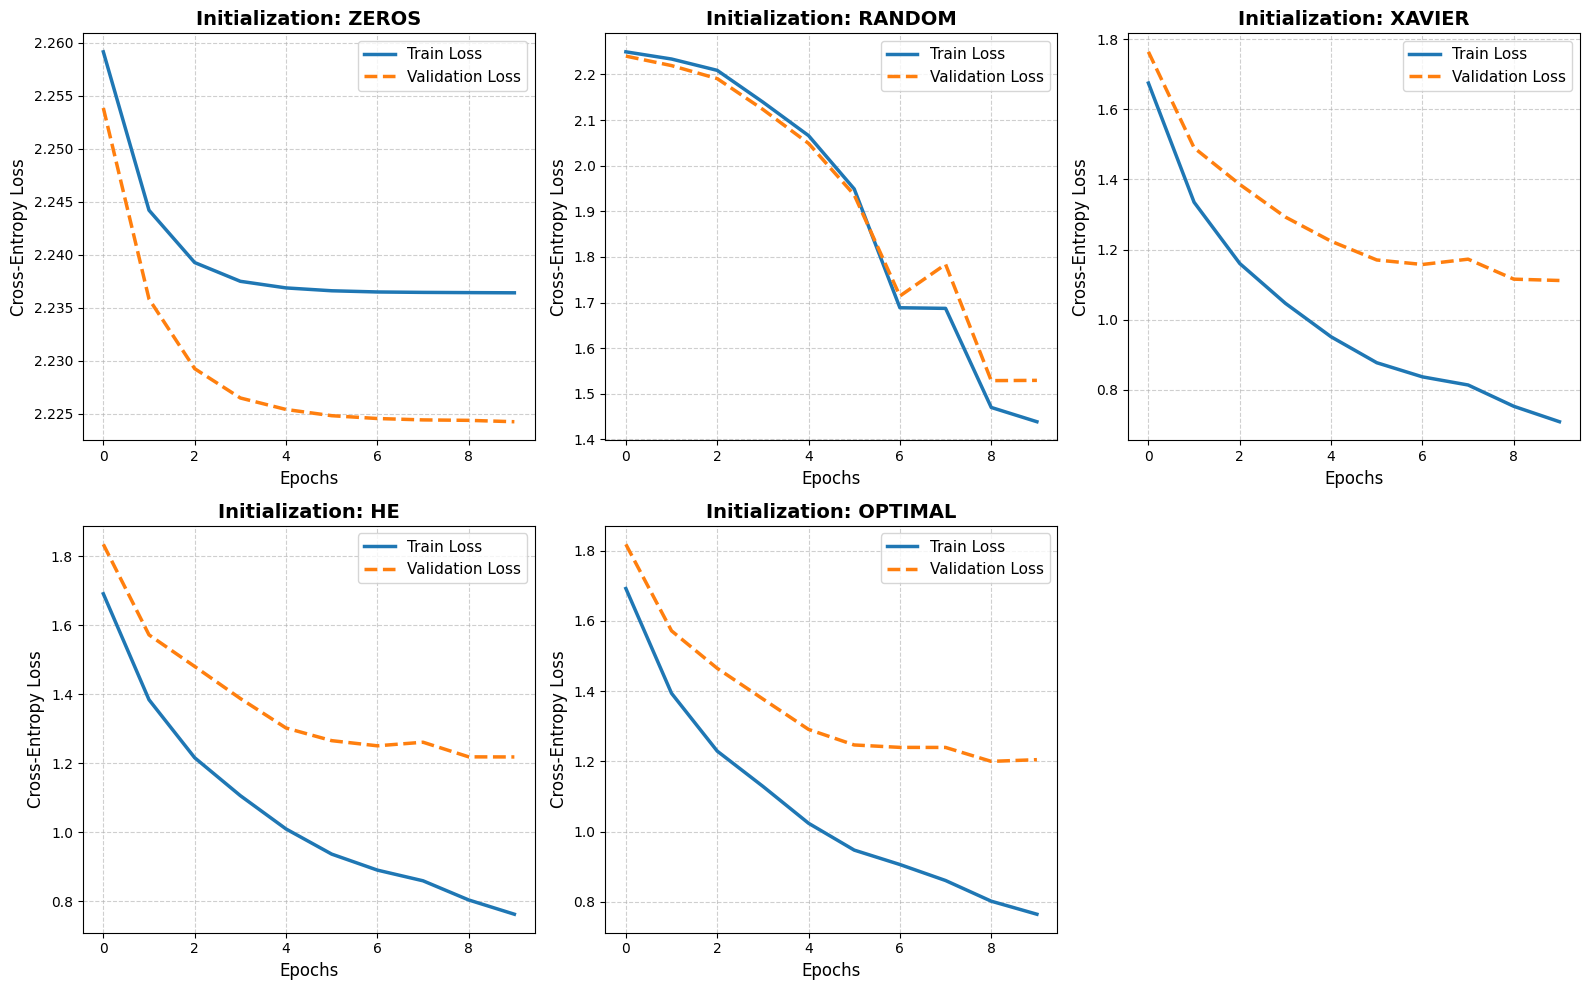

In [11]:
# Create a 2x3 grid of subplots (the 6th plot will be empty since we have 5 methods)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))
axes = axes.flatten()

# Colors for visual consistency
color_train = '#1f77b4' # Blue
color_val = '#ff7f0e'   # Orange

for i, (method, history) in enumerate(histories.items()):
    ax = axes[i]
    
    # Plot Train and Validation Loss
    ax.plot(history['train_loss'], label='Train Loss', color=color_train, linewidth=2.5)
    ax.plot(history['val_loss'], label='Validation Loss', color=color_val, linewidth=2.5, linestyle='--')
    
    ax.set_title(f'Initialization: {method.upper()}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Epochs', fontsize=12)
    ax.set_ylabel('Cross-Entropy Loss', fontsize=12)
    ax.legend(fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)

# Hide the 6th empty subplot
axes[5].axis('off')

# Adjust layout and display
plt.tight_layout()
plt.show()